# Лабораторная работа №2
## Виртуальный датчик для контроля процесса обжига в печи

На печи обжига концентрация продукта измеряется в лаборатории. Пробу забирают не каждую минуту, а результат приходит ещё через 10-15 минут. Оператор видит показатель поздно и неровно, по минутной телеметрии можно оценить концентрацию в момент пробы, не дожидаясь лаборатории.

Телеметрия лежит в `data_train.csv` и `data_test_small.csv`, замеры лаборатории в `target_train.csv` и `target_test_small.csv`.


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera

plt.style.use("seaborn-v0_8-whitegrid")

tele_train = pd.read_csv("data_train.csv", parse_dates=["datetime"])
tele_test = pd.read_csv("data_test_small.csv", parse_dates=["datetime"])
lab_train = pd.read_csv("target_train.csv")
lab_test = pd.read_csv("target_test_small.csv")
lab_train.columns = ["datetime", "target"]
lab_test.columns = ["datetime", "target"]
lab_train["datetime"] = pd.to_datetime(lab_train["datetime"])
lab_test["datetime"] = pd.to_datetime(lab_test["datetime"])


In [2]:
# если одна минута записана несколько раз, оставляем последнюю строку
def clean_telemetry(df):
    n_dup = int(df["datetime"].duplicated().sum())
    out = df.drop_duplicates("datetime", keep="last").set_index("datetime").sort_index()
    return out, n_dup

def clean_lab(df):
    return df.drop_duplicates("datetime").set_index("datetime").sort_index()

tele_train, n_dup_train = clean_telemetry(tele_train)
tele_test, n_dup_test = clean_telemetry(tele_test)
lab_train = clean_lab(lab_train)
lab_test = clean_lab(lab_test)

print("телеметрия train", tele_train.shape[0], "с", tele_train.index.min(), "по", tele_train.index.max())
full = pd.date_range(tele_train.index.min(), tele_train.index.max(), freq="min")
print("пропущенных минут", len(full) - len(tele_train))
print("дублей train", n_dup_train, "дублей test", n_dup_test)
print("лаборатория train", len(lab_train), "test", len(lab_test))
print("пропуски, доля")
miss = (
    tele_train.isna().mean()
    .round(3)
    .sort_values(ascending=False)
    .rename("доля пропусков")
    .rename_axis("датчик")
    .reset_index()
)
print(miss.to_string(index=False))


телеметрия train 317998 с 2019-03-01 00:01:00 по 2019-10-07 19:58:00
пропущенных минут 0
дублей train 1548 дублей test 196
лаборатория train 1773 test 318
пропуски, доля
      датчик  доля пропусков
telemetry_12           0.993
telemetry_13           0.993
telemetry_14           0.993
telemetry_15           0.993
 telemetry_0           0.000
 telemetry_1           0.000
 telemetry_2           0.000
 telemetry_3           0.000
 telemetry_4           0.000
 telemetry_5           0.000
 telemetry_6           0.000
 telemetry_7           0.000
 telemetry_8           0.000
 telemetry_9           0.000
telemetry_10           0.000
telemetry_11           0.000


Повторные метки сняты, пропущенных минут нет. Сетка идёт с 1 марта по 7 октября 2019, лишних строк в обучении 1548, на тесте 196.

Датчики 0-11 заполнены, датчики 12-15 пустые в 99% минут.


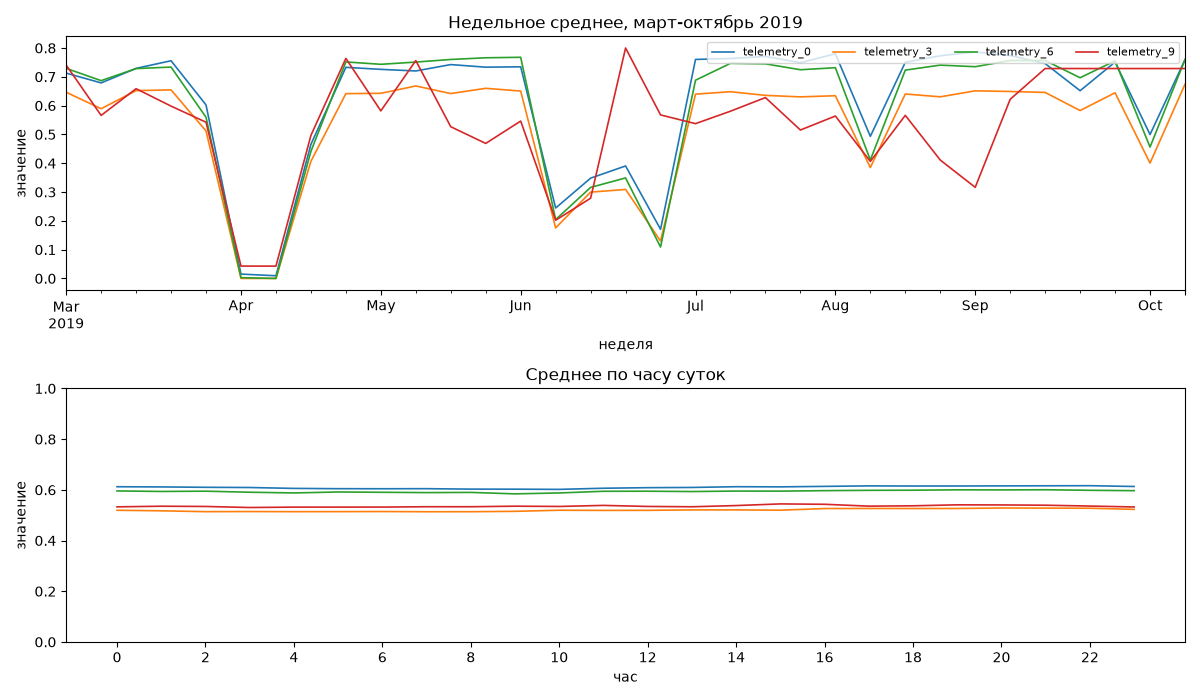

недельное среднее, минимум и максимум
      датчик  минимум  максимум
 telemetry_0    0.009     0.786
 telemetry_1    0.000     0.497
 telemetry_2    0.043     0.317
 telemetry_3    0.000     0.674
 telemetry_4    0.000     0.919
 telemetry_5    0.044     0.880
 telemetry_6    0.000     0.768
 telemetry_7    0.310     0.999
 telemetry_8    0.442     0.501
 telemetry_9    0.043     0.800
telemetry_10    0.042     0.810
telemetry_11    0.042     0.738
размах среднего по часу суток
      датчик  размах
 telemetry_0   0.015
 telemetry_1   0.014
 telemetry_2   0.005
 telemetry_3   0.015
 telemetry_4   0.018
 telemetry_5   0.007
 telemetry_6   0.016
 telemetry_7   0.012
 telemetry_8   0.003
 telemetry_9   0.014
telemetry_10   0.011
telemetry_11   0.017
датчик 0, размах внутри месяца
  месяц  размах по часу  размах по дню недели
2019-03           0.031                 0.206
2019-04           0.053                 0.100
2019-05           0.010                 0.008
2019-06           0.031     

In [13]:
dense = [f"telemetry_{i}" for i in range(12)]
show_cols = ["telemetry_0", "telemetry_3", "telemetry_6", "telemetry_9"]

# по минутам за весь срок линии сливаются, поэтому берём среднее за неделю
weekly = tele_train[show_cols].resample("W").mean()
by_hour = tele_train[show_cols].groupby(tele_train.index.hour).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
weekly.plot(ax=axes[0], linewidth=1.2)
axes[0].set_title("Недельное среднее, март-октябрь 2019")
axes[0].set_ylabel("значение")
axes[0].set_xlabel("неделя")
axes[0].legend(loc="upper right", ncol=4, fontsize=8)
# нижнюю ось ставим от 0 до 1, на одной шкале с недельным графиком
by_hour.plot(ax=axes[1], linewidth=1.2, legend=False)
axes[1].set_ylim(0, 1)
axes[1].set_title("Среднее по часу суток")
axes[1].set_xlabel("час")
axes[1].set_ylabel("значение")
axes[1].set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

level = tele_train[dense].resample("W").mean().agg(["min", "max"]).T.round(3)
level = level.rename(columns={"min": "минимум", "max": "максимум"}).rename_axis("датчик").reset_index()
print("недельное среднее, минимум и максимум")
print(level.to_string(index=False))

by_hour_all = tele_train[dense].groupby(tele_train.index.hour).mean()
hour_span = (
    (by_hour_all.max() - by_hour_all.min())
    .round(3)
    .rename("размах")
    .rename_axis("датчик")
    .reset_index()
)
print("размах среднего по часу суток")
print(hour_span.to_string(index=False))

t0 = tele_train["telemetry_0"]
month_rows = []
for period, g in t0.groupby(t0.index.to_period("M")):
    hour_r = g.groupby(g.index.hour).mean()
    dow_r = g.groupby(g.index.dayofweek).mean()
    month_rows.append({
        "месяц": str(period),
        "размах по часу": round(float(hour_r.max() - hour_r.min()), 3),
        "размах по дню недели": round(float(dow_r.max() - dow_r.min()), 3),
    })
month_tbl = pd.DataFrame(month_rows)
print("датчик 0, размах внутри месяца")
print(month_tbl.to_string(index=False))

# точный ноль и длина самого длинного куска
rows = []
for i in range(12):
    s = tele_train[f"telemetry_{i}"]
    is_zero = s.eq(0)
    if is_zero.any():
        groups = is_zero.ne(is_zero.shift()).cumsum()
        run_min = int(is_zero.groupby(groups).sum().max())
    else:
        run_min = 0
    rows.append({
        "датчик": f"telemetry_{i}",
        "доля нулей": round(float(is_zero.mean()), 3),
        "длинный ноль, сутки": round(run_min / 1440, 1),
    })
zero_tbl = pd.DataFrame(rows).sort_values("доля нулей", ascending=False)
print("доля нулей и самый длинный кусок")
print(zero_tbl.to_string(index=False))


Недельное среднее заметно меняется от недели к неделе, у датчика 0 оно опускается до 0.009 и поднимается до 0.786. В апреле и в июне к нулю вместе с ним садятся датчики 3 и 6, это остановки по много дней.

По часу суток размах среднего у плотных датчиков не больше 0.018, на шкале от 0 до 1 линии почти прямые.

По дню недели размах у датчика 0 в мае равен 0.008, дни в спокойный месяц похожи друг на друга. В июне размах равен 0.274, потому что часть недель стоит на нуле. Октябрь в обучении идёт только до 7 числа, размах 0.671 там даёт один такой простой.

Доля нулей у датчика 1 равна 0.204, у датчика 3 равна 0.188, у датчика 6 равна 0.187, у датчика 4 равна 0.133. Самый длинный кусок у датчика 1 длится 16.8 суток. Эти куски оставляем в ряде, для печи это остановка режима.


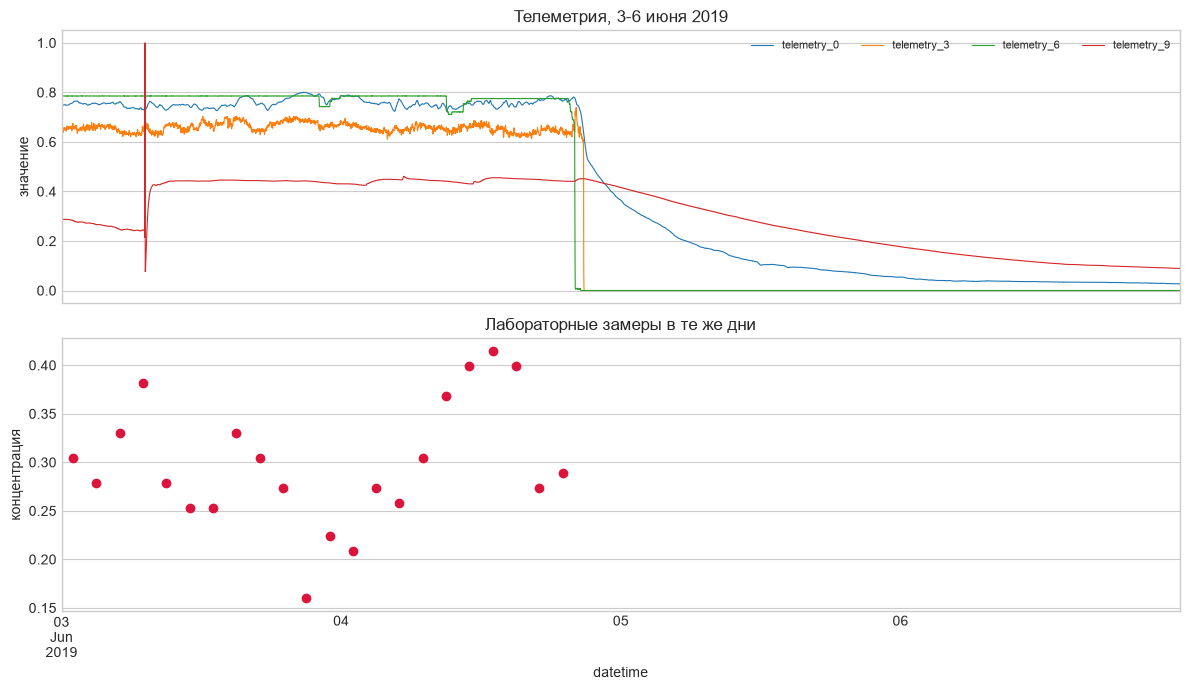

лаборатория train, промежуток в часах
показатель    часы
     count 1772.00
      mean    2.82
       std   13.07
       min    1.00
       25%    2.00
       50%    2.00
       75%    2.00
       max  440.50
час отбора
 час  число проб
   1         163
   3         132
   5         161
   6           1
   7         130
   8           1
   9         158
  10           2
  11         131
  13         161
  15         134
  17         165
  19         135
  21         165
  22           1
  23         133
минута отбора
 минута  число проб
      0        1772
     30           1
концентрация
показатель  концентрация
     count      1773.000
      mean         0.254
       std         0.092
       min         0.000
       25%         0.175
       50%         0.247
       75%         0.314
       max         0.716
нулей 1 выше 0.6 5


In [3]:
dense = [f"telemetry_{i}" for i in range(12)]
sparse = [f"telemetry_{i}" for i in range(12, 16)]

# рисуем только 3-6 июня, на всём ряде линии сливаются
sl = slice("2019-06-03", "2019-06-06")
view = tele_train.loc[sl, ["telemetry_0", "telemetry_3", "telemetry_6", "telemetry_9"]]
labs = lab_train.loc[sl]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
view.plot(ax=axes[0], linewidth=0.8)
axes[0].set_title("Телеметрия, 3-6 июня 2019")
axes[0].set_ylabel("значение")
axes[0].legend(loc="upper right", ncol=4, fontsize=8)
labs["target"].plot(ax=axes[1], style="o", color="crimson", legend=False)
axes[1].set_xlim(view.index.min(), view.index.max())
axes[1].set_title("Лабораторные замеры в те же дни")
axes[1].set_ylabel("концентрация")
plt.tight_layout()
plt.show()

print("лаборатория train, промежуток в часах")
gap_h = lab_train.index.to_series().diff().dt.total_seconds().div(3600).dropna()
gap_tbl = gap_h.describe().round(2).rename("часы").rename_axis("показатель").reset_index()
print(gap_tbl.to_string(index=False))
print("час отбора")
hour_tbl = (
    lab_train.index.hour.value_counts()
    .sort_index()
    .rename("число проб")
    .rename_axis("час")
    .reset_index()
)
print(hour_tbl.to_string(index=False))
print("минута отбора")
minute_tbl = (
    lab_train.index.minute.value_counts()
    .rename("число проб")
    .rename_axis("минута")
    .reset_index()
)
print(minute_tbl.to_string(index=False))
print("концентрация")
conc_tbl = (
    lab_train["target"].describe().round(3)
    .rename("концентрация")
    .rename_axis("показатель")
    .reset_index()
)
print(conc_tbl.to_string(index=False))
print("нулей", int((lab_train["target"] == 0).sum()), "выше 0.6", int((lab_train["target"] > 0.6).sum()))


In [4]:
# смотрим, в какие часы есть отметки датчика 12
sparse_times = tele_train["telemetry_12"].dropna().index
print("датчик 12, число отметок", len(sparse_times))
print("промежуток, минуты")
gap_min = sparse_times.to_series().diff().dt.total_seconds().div(60).describe().round(1)
gap_tbl = gap_min.rename("минуты").rename_axis("показатель").reset_index()
print(gap_tbl.to_string(index=False))
print("час отметки")
hour_tbl = (
    sparse_times.hour.value_counts()
    .sort_index()
    .rename("число отметок")
    .rename_axis("час")
    .reset_index()
)
print(hour_tbl.to_string(index=False))


датчик 12, число отметок 2097
промежуток, минуты
показатель  минуты
     count  2096.0
      mean   151.6
       std   717.9
       min    60.0
       25%   120.0
       50%   120.0
       75%   120.0
       max 26280.0
час отметки
 час  число отметок
   0            175
   2            174
   4            173
   6            175
   8            174
  10            172
  12            174
  14            175
  16            175
  17              1
  18            176
  20            177
  22            176


Лаборатория ходит примерно раз в два часа. Медианный промежуток 2 часа, хвост длинный, есть разрыв больше двух недель. Почти все пробы стоят на ровном часе и в нечётный час. Средняя концентрация около 0.25, один ноль и пять значений выше 0.6. Это редкие края, их не выбрасываем, для контроля печи как раз важны плохие режимы.

Датчики 12-15 приходят тоже примерно раз в два часа, но в чётный час, это другой поток, не сама проба. Пустую минуту у них не заменяем нулём, длинный простой не протягиваем на дни.


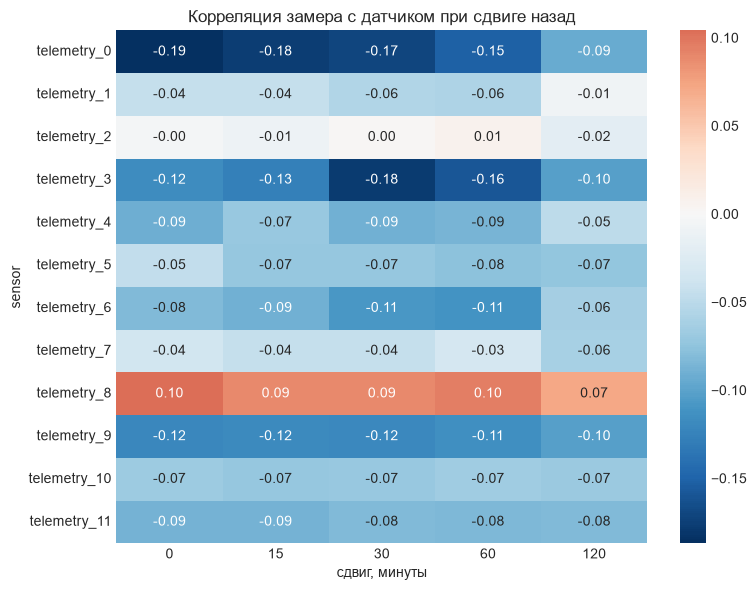

сдвиг, минуты  средняя абсолютная корреляция
             0                          0.082
            15                          0.084
            30                          0.091
            60                          0.087
           120                          0.067


In [5]:
# связь пробы с телеметрией при разном сдвиге назад
lags = [0, 15, 30, 60, 120]
rows = []
for lag in lags:
    joined = lab_train.join(tele_train[dense].shift(lag), how="inner")
    for col in dense:
        rows.append((lag, col, joined[col].corr(joined["target"])))
lag_corr = pd.DataFrame(rows, columns=["lag_min", "sensor", "corr"])
heat = lag_corr.pivot(index="sensor", columns="lag_min", values="corr")
heat = heat.reindex([f"telemetry_{i}" for i in range(12)])

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(heat, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Корреляция замера с датчиком при сдвиге назад")
ax.set_xlabel("сдвиг, минуты")
plt.tight_layout()
plt.show()

mean_abs = (
    lag_corr.groupby("lag_min")["corr"]
    .apply(lambda s: s.abs().mean())
    .round(3)
    .rename("средняя абсолютная корреляция")
    .reset_index()
    .rename(columns={"lag_min": "сдвиг, минуты"})
)
print(mean_abs.to_string(index=False))


Задержка лаборатории на 10-15 минут картину почти не меняет. Средняя абсолютная корреляция 0.082 в ту же минуту и 0.084 через 15 минут, на 30 минутах она выше и равна 0.091, к двум часам она падает до 0.067.

Метку пробы оставляем на её времени, в признаки берём значение в эту минуту, сдвиг на 30 минут и среднее за 30 минут. За два часа берём среднее, разброс, минимум и максимум, приращение считаем за 30 минут, два часа здесь обычный шаг самой лаборатории.


In [6]:
def telemetry_features(tele):
    parts = []
    for i in range(12):
        s = tele[f"telemetry_{i}"]
        parts.append(pd.DataFrame({
            f"t{i}_now": s,
            f"t{i}_l30": s.shift(30),
            f"t{i}_l120": s.shift(120),
            f"t{i}_m30": s.rolling(30, min_periods=15).mean(),
            f"t{i}_m120": s.rolling(120, min_periods=60).mean(),
            f"t{i}_s120": s.rolling(120, min_periods=60).std(),
            f"t{i}_min120": s.rolling(120, min_periods=60).min(),
            f"t{i}_max120": s.rolling(120, min_periods=60).max(),
            f"t{i}_d30": s.diff(30),
        }))
    # для датчиков 12-15 берём последнее значение, если оно не старше 3 часов
    for i in range(12, 16):
        parts.append(tele[f"telemetry_{i}"].ffill(limit=180).rename(f"t{i}_last").to_frame())
    return pd.concat(parts, axis=1)

tele_all = pd.concat([tele_train, tele_test])
tele_all = tele_all[~tele_all.index.duplicated(keep="last")].sort_index()
feat_all = telemetry_features(tele_all)

lab_all = pd.concat([lab_train, lab_test])
lab_all = lab_all[~lab_all.index.duplicated(keep="last")].sort_index()
# в признаки кладём прошлую пробу, текущую пробу туда не кладём
prev_lab = lab_all["target"].shift(1).rename("prev_lab")
hours_since = (lab_all.index.to_series().diff().dt.total_seconds() / 3600).rename("hours_since_lab")

def samples(lab):
    frame = lab.join(feat_all, how="left").join(prev_lab, how="left").join(hours_since, how="left")
    return frame.dropna()

train = samples(lab_train)
test = samples(lab_test)
feat_cols = [c for c in train.columns if c != "target"]
print("пробы train", len(train), "test", len(test), "признаков", len(feat_cols))
print("корреляция признаков с концентрацией, верх списка")
top_corr = (
    train[feat_cols].corrwith(train["target"]).abs()
    .sort_values(ascending=False)
    .head(12)
    .round(3)
    .rename("абсолютная корреляция")
    .rename_axis("признак")
    .reset_index()
)
print(top_corr.to_string(index=False))


пробы train 1766 test 318 признаков 114
корреляция признаков с концентрацией, верх списка
  признак  абсолютная корреляция
 prev_lab                  0.544
 t15_last                  0.189
t0_max120                  0.149
   t0_now                  0.140
t9_min120                  0.139
   t0_m30                  0.137
 t12_last                  0.135
t7_min120                  0.132
   t0_l30                  0.129
   t9_now                  0.123
   t9_m30                  0.123
   t9_l30                  0.122


Сильнее всего с новой пробой связана прошлая, корреляция около 0.54. Концентрация между отборами меняется медленно, поэтому последний лабораторный номер уже многое говорит. Телеметрия добавляет остальное, дальше идут редкая отметка датчика 15, датчик 0, затем датчики 9, 12 и 7.

PCA не делаем, оператору нужен конкретный датчик, смесь компонент ему ничего не скажет.


Минутный ARIMA или SARIMAX сюда не садится, концентрация известна не каждую минуту, а раз в пару часов. Тянуть авторегрессию через тысячи минут без замера не из чего.

Prophet ждёт ровный календарный ряд, здесь отклик сидит на многих датчиках, а часы лаборатории не совпадают с чётными отметками датчиков 12-15.

LSTM и трансформер примерно на 1800 пробах легко запоминают обучение, потом оператору нечего показать, кроме самого графика.

Берём три модели на одной и той же таблице признаков, гребневую регрессию, случайный лес и градиентный бустинг по гистограммам, рядом кладём ориентир, просто предыдущую пробу, без телеметрии.


In [7]:
X_train = train[feat_cols]
y_train = train["target"]
X_test = test[feat_cols]
y_test = test["target"]

def point_metrics(y, pred):
    pred = pd.Series(np.asarray(pred), index=y.index)
    mae = mean_absolute_error(y, pred)
    rmse = mean_squared_error(y, pred) ** 0.5
    positive = y > 0
    mape = np.mean(np.abs((y[positive] - pred[positive]) / y[positive])) * 100
    wape = np.sum(np.abs(y - pred)) / np.sum(np.abs(y)) * 100
    # знак изменения между соседними пробами
    dy = np.sign(y.diff())
    dp = np.sign(pred.diff())
    both = (dy != 0) & (dp != 0)
    direction = float((dy[both] == dp[both]).mean())
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "WAPE": wape, "направление": direction}

fitted = {}
pred_test = {}
rows = []

t0 = time.perf_counter()
pred_test["прошлая проба"] = X_test["prev_lab"]
rows.append({"модель": "прошлая проба", "секунды": 0.0, **point_metrics(y_test, pred_test["прошлая проба"])})

t0 = time.perf_counter()
fitted["гребневая"] = Ridge(alpha=1.0).fit(X_train, y_train)
pred_test["гребневая"] = fitted["гребневая"].predict(X_test)
rows.append({"модель": "гребневая", "секунды": time.perf_counter() - t0, **point_metrics(y_test, pred_test["гребневая"])})

t0 = time.perf_counter()
fitted["лес"] = RandomForestRegressor(
    n_estimators=300, max_depth=10, min_samples_leaf=3, random_state=0, n_jobs=-1
).fit(X_train, y_train)
pred_test["лес"] = fitted["лес"].predict(X_test)
rows.append({"модель": "лес", "секунды": time.perf_counter() - t0, **point_metrics(y_test, pred_test["лес"])})

t0 = time.perf_counter()
fitted["бустинг"] = HistGradientBoostingRegressor(
    max_depth=4, learning_rate=0.06, max_iter=250, random_state=0
).fit(X_train, y_train)
pred_test["бустинг"] = fitted["бустинг"].predict(X_test)
rows.append({"модель": "бустинг", "секунды": time.perf_counter() - t0, **point_metrics(y_test, pred_test["бустинг"])})

metrics = pd.DataFrame(rows).set_index("модель")
print(metrics.round(3))


               секунды    MAE   RMSE    MAPE    WAPE  направление
модель                                                           
прошлая проба    0.000  0.059  0.080  29.717  28.368        0.365
гребневая        0.002  0.051  0.067  27.870  24.537        0.480
лес              0.906  0.054  0.069  29.411  25.559        0.450
бустинг          0.790  0.053  0.068  27.816  25.165        0.497


У предыдущей пробы MAE 0.059 и RMSE 0.080, направление она угадывает только в 37% шагов. Просто повторять лабораторию мало, когда режим печи уже уехал.

Гребневая регрессия снижает MAE до 0.051 и RMSE до 0.067, направление у неё 0.48. Бустинг по MAE 0.053, направление 0.50, лес чуть хуже по ошибке. Лес и бустинг считаются дольше гребневой, но укладываются в секунду.


меньшая MAE гребневая


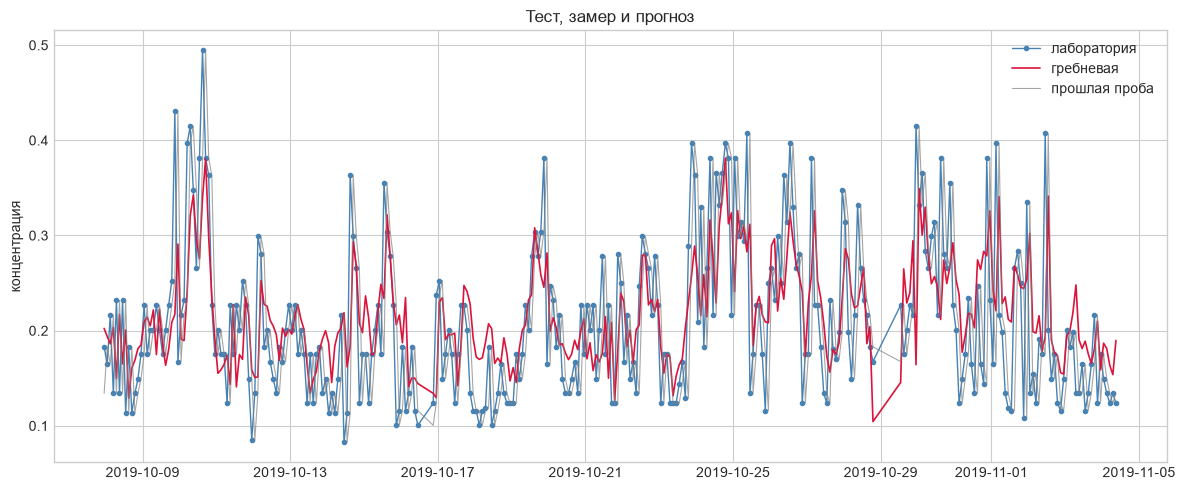

In [8]:
# для графика берём модель с меньшей MAE и не включаем в этот выбор прошлую пробу
learned = metrics.drop(index="прошлая проба")
best_name = learned["MAE"].idxmin()
print("меньшая MAE", best_name)
best_pred = pd.Series(pred_test[best_name], index=y_test.index)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y_test.index, y_test.values, color="steelblue", marker="o", markersize=3, linewidth=1.0, label="лаборатория")
ax.plot(best_pred.index, best_pred.values, color="crimson", linewidth=1.2, label=best_name)
ax.plot(X_test.index, X_test["prev_lab"].values, color="gray", linewidth=0.8, alpha=0.7, label="прошлая проба")
ax.set_title("Тест, замер и прогноз")
ax.set_ylabel("концентрация")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


In [9]:
resid = y_test - best_pred
resid = resid.dropna()
fitted_values = best_pred.loc[resid.index]

jb_stat, jb_p, _, _ = jarque_bera(resid)
dw = durbin_watson(resid)
lb = acorr_ljungbox(resid, lags=[1, 6], return_df=True)
bp = het_breuschpagan(resid, sm.add_constant(fitted_values))
print(f"модель: {best_name}")
print(f"Jarque-Bera p-value: {jb_p:.3f}")
print(f"Durbin-Watson: {dw:.3f}")
print(f"Ljung-Box p, лаг 1: {lb.loc[1, 'lb_pvalue']:.3f}")
print(f"Ljung-Box p, лаг 6: {lb.loc[6, 'lb_pvalue']:.3f}")
print(f"Breusch-Pagan p: {bp[1]:.3f}")


модель: гребневая
Jarque-Bera p-value: 0.000
Durbin-Watson: 2.132
Ljung-Box p, лаг 1: 0.165
Ljung-Box p, лаг 6: 0.009
Breusch-Pagan p: 0.010


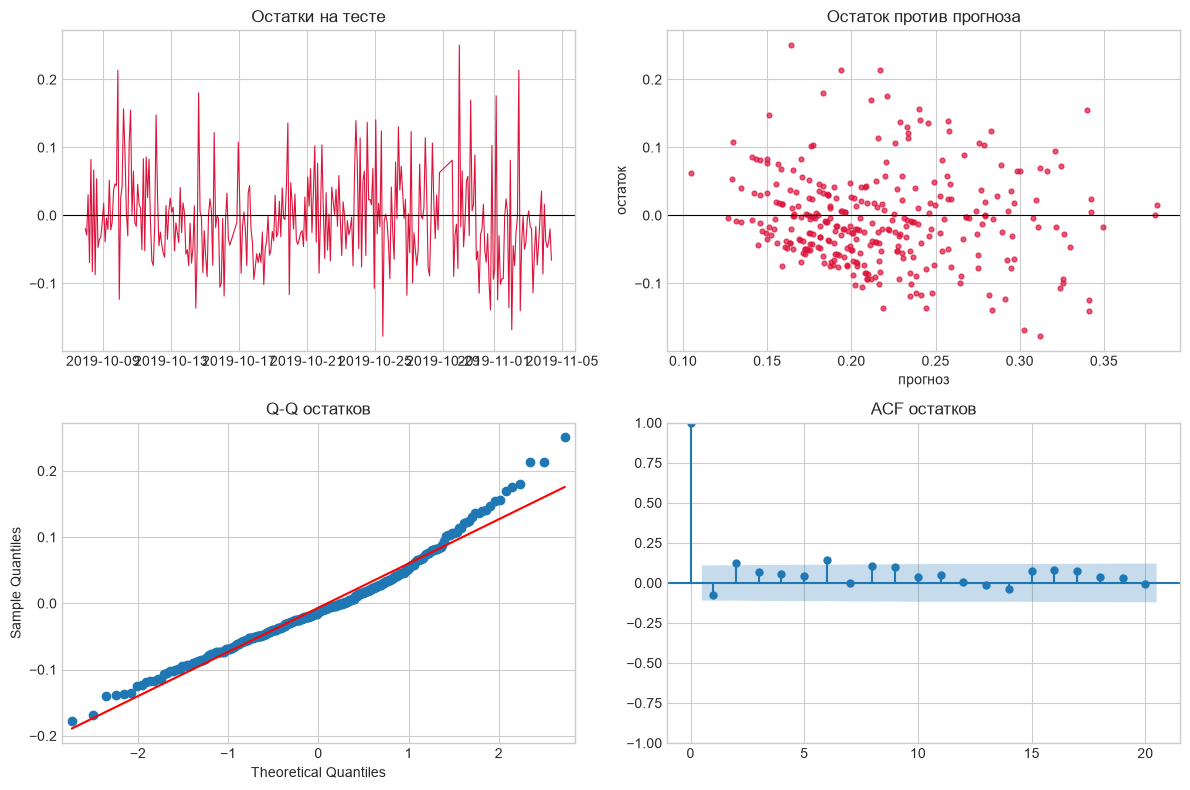

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(resid.index, resid.values, color="crimson", linewidth=0.8)
axes[0, 0].axhline(0, color="black", linewidth=0.8)
axes[0, 0].set_title("Остатки на тесте")
axes[0, 1].scatter(fitted_values, resid, s=12, color="crimson", alpha=0.7)
axes[0, 1].axhline(0, color="black", linewidth=0.8)
axes[0, 1].set_xlabel("прогноз")
axes[0, 1].set_ylabel("остаток")
axes[0, 1].set_title("Остаток против прогноза")
sm.qqplot(resid, line="s", ax=axes[1, 0])
axes[1, 0].set_title("Q-Q остатков")
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(resid, lags=20, ax=axes[1, 1], title="ACF остатков")
plt.tight_layout()
plt.show()


Остатки гребневой модели на тесте не нормальны, Jarque-Bera p-value 0.000. Разброс неровный, Бройш-Паган p-value 0.010. Соседние пробы почти не связаны, Льюнг-Бокс на лаге 1 даёт 0.165, Дарбин-Уотсон 2.13. На лаге 6 связь ещё есть, p-value 0.009. Крупные ошибки сидят на редких режимах.


  признак  рост MAE
 prev_lab    0.0130
 t15_last    0.0014
   t0_now    0.0012
   t0_m30    0.0009
   t0_l30    0.0007
  t6_l120    0.0005
  t6_m120    0.0005
   t6_l30    0.0003
 t14_last    0.0003
   t6_now    0.0003
  t0_m120    0.0002
t0_max120    0.0002


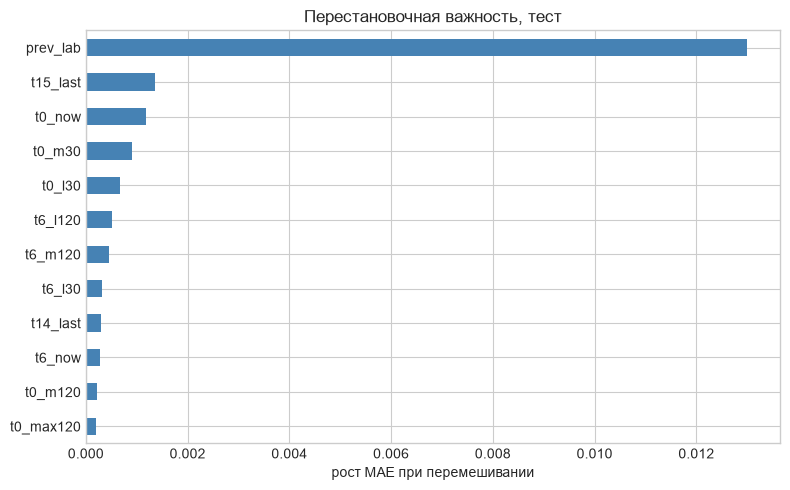

In [11]:
# на тесте перемешиваем признаки у модели с меньшей MAE и смотрим рост ошибки
perm = permutation_importance(
    fitted[best_name], X_test, y_test,
    n_repeats=5, random_state=0, scoring="neg_mean_absolute_error", n_jobs=-1,
)
imp = pd.Series(perm.importances_mean, index=feat_cols).sort_values(ascending=False)
imp_tbl = imp.head(12).round(4).rename("рост MAE").rename_axis("признак").reset_index()
print(imp_tbl.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
imp.head(12).sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Перестановочная важность, тест")
ax.set_xlabel("рост MAE при перемешивании")
plt.tight_layout()
plt.show()


Почти весь рост ошибки на тесте даёт прошлая проба, следом идут последняя отметка датчика 15 и текущий датчик 0 вместе с его окном в 30 минут. Остальные признаки двигают ошибку слабо. Пока новая проба не пришла, держим последний лабораторный номер и поправляем его по датчику 0.


In [12]:
# AIC и BIC считаем только у линейных формул и сравниваем эти формулы между собой
ols_sets = {
    "только прошлая проба": ["prev_lab"],
    "прошлая проба и датчик 0": ["prev_lab", "t0_now", "t0_l30", "t0_m120"],
    "прошлая проба и несколько датчиков": [
        "prev_lab", "t0_now", "t9_now", "t3_m120", "t15_last", "t12_last", "hours_since_lab"
    ],
}
ols_rows = []
for name, cols in ols_sets.items():
    exog_train = sm.add_constant(X_train[cols], has_constant="add")
    exog_test = sm.add_constant(X_test[cols], has_constant="add")
    model = sm.OLS(y_train, exog_train).fit()
    pred = model.predict(exog_test)
    ols_rows.append({
        "спецификация": name,
        "AIC": model.aic,
        "BIC": model.bic,
        "MAE": mean_absolute_error(y_test, pred),
    })
ols_table = pd.DataFrame(ols_rows).set_index("спецификация")
show = ols_table.copy()
show["MAE"] = show["MAE"].round(3)
show["AIC"] = show["AIC"].round(1)
show["BIC"] = show["BIC"].round(1)
print(show)


                                       AIC     BIC    MAE
спецификация                                             
только прошлая проба               -4072.2 -4061.2  0.057
прошлая проба и датчик 0           -4120.1 -4092.8  0.054
прошлая проба и несколько датчиков -4188.6 -4144.8  0.053


**Вывод по качеству.** На тесте у прошлой пробы MAE 0.059 и RMSE 0.080. Гребневая регрессия даёт MAE 0.051 и RMSE 0.067, выигрыш около 0.008 по MAE. Направление с 0.37 поднимается до 0.48 у гребневой и до 0.50 у бустинга, половина шагов всё ещё в другую сторону. Датчик полезен как подсказка между пробами, а не как замена лаборатории.

AIC и BIC считаем только у обычной регрессии, лес и бустинг сюда не входят, у них нет такого правдоподобия. Одна прошлая проба даёт AIC -4072 и MAE на тесте 0.057. С датчиком 0 AIC -4120 и MAE 0.054. Несколько датчиков дают AIC -4188 и MAE 0.053. И критерий, и тест двигаются в одну сторону, телеметрию в линейной формуле оставляем.

Как рабочую модель берём гребневую регрессию, у неё меньшая MAE среди трёх обученных, 0.051, и она считается за доли секунды. Прошлая проба в ней главный член, датчики поправляют. Бустинг даёт почти ту же ошибку и показывает, что дерево заметно лучше не становится.
